# Лабораторная работа 2 (часть 2)
## Прикладные задачи на данных интернет-магазина
**ФИО:** Янчук Антон
**Группа:** ЕТ-216

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Фиксируем генератор случайных чисел по требованию методички
np.random.seed(2024)

n_orders = 3000

# Справочники для генерации категориальных признаков
cities = ["Москва", "Санкт-Петербург", "Казань", "Екатеринбург", "Челябинск"]
categories = ["Электроника", "Одежда", "Дом", "Красота", "Спорт"]
statuses = ["Доставлен", "Отменён", "Возврат"]
payments = ["Карта", "Онлайн", "Наличные"]

# Соответствие категорий и типичных товаров
products_by_category = {
    "Электроника": ["Смартфон", "Наушники", "Ноутбук", "Смарт-часы", "Планшет"],
    "Одежда": ["Джинсы", "Худи", "Куртка", "Футболка", "Кроссовки"],
    "Дом": ["Пылесос", "Увлажнитель воздуха", "Комплект постельного белья", "Кофеварка", "Лампа"],
    "Красота": ["Парфюм", "Крем для лица", "Набор кистей", "Шампунь", "Сыворотка"],
    "Спорт": ["Гантели", "Коврик для йоги", "Фитнес-резинки", "Велотренажер", "Бутылка для воды"]
}

# Генерация базовых атрибутов заказов
order_ids = np.arange(10001, 10001 + n_orders)
customer_ids = np.random.randint(101, 700, size=n_orders) # ~600 уникальных покупателей

# Случайные даты в диапазоне 2024 года
random_days = np.random.randint(0, 365, size=n_orders)
order_dates = pd.to_datetime("2024-01-01") + pd.to_timedelta(random_days, unit="D")

assigned_cities = np.random.choice(cities, size=n_orders, p=[0.35, 0.25, 0.15, 0.15, 0.10])
ages = np.random.randint(16, 75, size=n_orders).astype(float)
is_vip = np.random.choice([True, False], size=n_orders, p=[0.15, 0.85])

assigned_categories = np.random.choice(categories, size=n_orders)
assigned_products = [np.random.choice(products_by_category[cat]) for cat in assigned_categories]

quantities = np.random.randint(1, 6, size=n_orders)

# Базовые цены и скидки
base_prices = {
    "Электроника": (4000, 45000),
    "Одежда": (1200, 9000),
    "Дом": (1500, 16000),
    "Красота": (800, 7000),
    "Спорт": (1000, 14000)
}
prices = np.array([np.random.randint(base_prices[cat][0], base_prices[cat][1]) for cat in assigned_categories])
discounts = np.random.choice([0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30], size=n_orders, p=[0.3, 0.2, 0.15, 0.15, 0.1, 0.05, 0.05])

# Себестоимость формируется от базовой цены с добавлением случайных накладных расходов (логистика/закупка)
# При больших скидках или высоких издержках прибыль может стать отрицательной
costs = np.round(prices * quantities * np.random.uniform(0.65, 0.95, size=n_orders), 2)

assigned_statuses = np.random.choice(statuses, size=n_orders, p=[0.75, 0.15, 0.10])
assigned_payments = np.random.choice(payments, size=n_orders, p=[0.50, 0.35, 0.15])

# Сборка датафрейма
df = pd.DataFrame({
    "order_id": order_ids,
    "order_date": order_dates,
    "customer_id": customer_ids,
    "city": assigned_cities,
    "age": ages,
    "is_vip": is_vip,
    "product_name": assigned_products,
    "category": assigned_categories,
    "quantity": quantities,
    "price": prices,
    "discount": discounts,
    "cost": costs,
    "status": assigned_statuses,
    "payment": assigned_payments
})

# Добавляем ровно 30 случайных пропусков (NaN) в возраст по требованию методички
nan_indices = np.random.choice(df.index, size=30, replace=False)
df.loc[nan_indices, "age"] = np.nan

print(f"Датасет успешно сформирован! Размерность: {df.shape}")
df.head(3)

Датасет успешно сформирован! Размерность: (3000, 14)


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment
0,10001,2024-04-07,607,Екатеринбург,27.0,False,Смарт-часы,Электроника,3,14616,0.00,33793.11,Доставлен,Онлайн
1,10002,2024-12-16,640,Челябинск,20.0,False,Увлажнитель воздуха,Дом,4,3567,0.05,11958.31,Доставлен,Наличные
2,10003,2024-06-28,649,Санкт-Петербург,29.0,False,Бутылка для воды,Спорт,3,10142,0.00,28276.73,Доставлен,Карта


In [2]:
# 1. Размерность таблицы
print("1. Размерность датафрейма (строки, столбцы):", df.shape)

# 2. Первые и последние строки
print("\n2. Первые 3 строки:")
display(df.head(3))

print("\nПоследние 3 строки:")
display(df.tail(3))

# 3. Общая техническая информация
print("\n3. Сводная информация о типах и заполнении:")
df.info()

# 4. Пропущенные значения
print("\n4. Количество пропущенных значений по столбцам:")
print(df.isna().sum())

# 5. Описательная статистика числовых столбцов
print("\n5. Описательная статистика:")
display(df.describe())

# 6. Дополнительные проверки для ответов на контрольные вопросы
print("\n6. Уникальные клиенты:", df["customer_id"].nunique())
print("Уникальные товары:", df["product_name"].nunique())
print("Города в выборке:", df["city"].unique().tolist())
print("Категории товаров:", df["category"].unique().tolist())
print("Способы оплаты:", df["payment"].unique().tolist())

1. Размерность датафрейма (строки, столбцы): (3000, 14)

2. Первые 3 строки:


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment
0,10001,2024-04-07,607,Екатеринбург,27.0,False,Смарт-часы,Электроника,3,14616,0.00,33793.11,Доставлен,Онлайн
1,10002,2024-12-16,640,Челябинск,20.0,False,Увлажнитель воздуха,Дом,4,3567,0.05,11958.31,Доставлен,Наличные
2,10003,2024-06-28,649,Санкт-Петербург,29.0,False,Бутылка для воды,Спорт,3,10142,0.00,28276.73,Доставлен,Карта



Последние 3 строки:


,order_id,order_date,customer_id,city,age,is_vip,product_name,category,quantity,price,discount,cost,status,payment
2997,12998,2024-05-06,361,Москва,56.0,False,Смарт-часы,Электроника,1,38333,0.05,32746.23,Возврат,Онлайн
2998,12999,2024-08-24,274,Екатеринбург,35.0,False,Пылесос,Дом,3,3170,0.05,6505.21,Доставлен,Онлайн
2999,13000,2024-11-22,137,Казань,59.0,False,Лампа,Дом,5,12331,0.00,45826.49,Доставлен,Наличные



3. Сводная информация о типах и заполнении:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      3000 non-null   int64         
 1   order_date    3000 non-null   datetime64[ns]
 2   customer_id   3000 non-null   int64         
 3   city          3000 non-null   object        
 4   age           2970 non-null   float64       
 5   is_vip        3000 non-null   bool          
 6   product_name  3000 non-null   object        
 7   category      3000 non-null   object        
 8   quantity      3000 non-null   int64         
 9   price         3000 non-null   int64         
 10  discount      3000 non-null   float64       
 11  cost          3000 non-null   float64       
 12  status        3000 non-null   object        
 13  payment       3000 non-null   object        
dtypes: bool(1), datetime64[ns](1), float64(3), 

,order_id,order_date,customer_id,age,quantity,price,discount,cost
count,3000.000000,3000,3000.000000,2970.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,11500.500000,2024-07-03 16:57:36,406.093667,45.089226,3.002333,9842.702000,0.094167,23545.553073
min,10001.000000,2024-01-01 00:00:00,101.000000,16.000000,1.000000,809.000000,0.000000,570.370000
25%,10750.750000,2024-04-05 00:00:00,251.000000,30.000000,2.000000,3979.500000,0.000000,6895.325000
50%,11500.500000,2024-07-03 00:00:00,413.000000,45.000000,3.000000,6678.000000,0.050000,14460.475000
75%,12250.250000,2024-10-01 00:00:00,554.250000,60.000000,4.000000,11789.250000,0.150000,28285.530000
max,13000.000000,2024-12-30 00:00:00,699.000000,74.000000,5.000000,44985.000000,0.300000,193384.320000
std,866.169729,NaN,174.061729,17.130700,1.422557,9403.320453,0.089071,27373.041789



6. Уникальные клиенты: 595
Уникальные товары: 25
Города в выборке: ['Екатеринбург', 'Челябинск', 'Санкт-Петербург', 'Казань', 'Москва']
Категории товаров: ['Электроника', 'Дом', 'Спорт', 'Красота', 'Одежда']
Способы оплаты: ['Онлайн', 'Наличные', 'Карта']


### Часть 1. Ответы на вопросы по структуре данных

1. **Сколько строк и столбцов в DataFrame?**
   - 3 000 строк и 14 столбцов (размерность `(3000, 14)`).
2. **В каких столбцах есть пропуски?**
   - Пропуски присутствуют только в одном столбце — `age` (возраст клиента). Все остальные 13 столбцов заполнены на 100%.
3. **Сколько пропусков в age?**
   - Ровно 30 пропущенных значений (`NaN`).
4. **Сколько уникальных клиентов?**
   - 595 уникальных покупателей (идентификаторы `customer_id` сгенерированы в диапазоне от 101 до 699, что отражает повторные покупки).
5. **Сколько уникальных товаров?**
   - 25 уникальных наименований товаров (по 5 товаров в каждой из 5 товарных категорий).
6. **Какие города представлены в данных?**
   - Москва, Санкт-Петербург, Казань, Екатеринбург, Челябинск.
7. **Какие категории товаров есть?**
   - Электроника, Одежда, Дом, Красота, Спорт.
8. **Какие способы оплаты используются?**
   - Карта, Онлайн, Наличные.

In [3]:
# 2.1. Работа с датами
df["order_date"] = pd.to_datetime(df["order_date"])
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month

# 2.2. Расчет выручки (revenue) и операционной прибыли (profit)
# Выручка = цена * количество * (1 - скидка)
df["revenue"] = df["price"] * df["quantity"] * (1 - df["discount"])

# Прибыль = выручка - себестоимость
df["profit"] = df["revenue"] - df["cost"]

# 2.3. Создание флага реальной продажи (доставленный заказ)
df["is_real_sale"] = df["status"] == "Доставлен"

# 2.4. Заполнение пропусков в возрасте медианным значением
median_age = df["age"].median()
df["age"] = df["age"].fillna(median_age)

print(f"Медианный возраст для заполнения: {median_age}")
print(f"Количество оставшихся пропусков в возрасте: {df['age'].isna().sum()}")

# 2.5. Сегментация на возрастные группы с помощью pd.cut()
bins = [0, 18, 30, 45, 60, 100]
labels = ["до 18", "18-30", "31-45", "46-60", "60+"]
df["age_group"] = pd.cut(df["age"], bins=bins, labels=labels)

print("\nКоличество заказов по возрастным группам:")
print(df["age_group"].value_counts(sort=False))

# Выводим первые строки для проверки новых колонок
print("\nПроверка новых признаков:")
df[["order_date", "year", "month", "revenue", "profit", "is_real_sale", "age_group"]].head(3)

Медианный возраст для заполнения: 45.0
Количество оставшихся пропусков в возрасте: 0

Количество заказов по возрастным группам:
age_group
до 18    148
18-30    613
31-45    773
46-60    750
60+      716
Name: count, dtype: int64

Проверка новых признаков:


,order_date,year,month,revenue,profit,is_real_sale,age_group
0,2024-04-07,2024,4,43848.0,10054.89,True,18-30
1,2024-12-16,2024,12,13554.6,1596.29,True,18-30
2,2024-06-28,2024,6,30426.0,2149.27,True,18-30


### Ответы на контрольные вопросы к Части 2

1. **Почему прибыль (profit) может оказаться отрицательной?**
   - Прибыль становится отрицательной ($profit < 0$), когда себестоимость ($cost$) превышает полученную выручку ($revenue$). В реальном бизнесе это происходит из-за:
     - Предоставления чрезмерно больших скидок или распродаж по ликвидационным ценам ниже порога рентабельности.
     - Высоких логистических, складских и закупочных издержек на единицу товара.
     - Продажи товаров-локомотивов в убыток ради привлечения клиентской базы.

2. **Почему при расчёте фактической выручки интернет-магазина имеет смысл учитывать только доставленные заказы (`is_real_sale`)?**
   - Если заказ был **отменён** клиентом или оформлен **возврат**, интернет-магазин не получает денег (или возвращает их покупателю). Включение отмененных и возвращенных товаров в финансовую отчетность искусственно завышает реальные показатели продаж и искажает финансовую аналитику компании.

3. **Зачем пропуски в возрасте заполнять медианой (`median`), а не средним (`mean`)?**
   - Медиана устойчива к случайным выбросам и экстремальным значениям. Кроме того, среднее значение часто дает дробное число (например, 41.3 года), в то время как медиана на целочисленных данных лучше сохраняет естественную структуру распределения.

In [4]:
# Задание 1. Заказы, где количество товаров больше 3
q_gt_3 = df[df["quantity"] > 3]
print(f"1. Заказов с количеством > 3: {len(q_gt_3)}")

# Задание 2. Заказы клиентов из Москвы
moscow_orders = df[df["city"] == "Москва"]
print(f"2. Заказов из Москвы: {len(moscow_orders)}")

# Задание 3. VIP-заказы
vip_orders = df[df["is_vip"]]
print(f"3. VIP-заказов: {len(vip_orders)}")

# Задание 4. Заказы, где цена товара больше 5000 рублей
price_gt_5000 = df[df["price"] > 5000]
print(f"4. Заказов с ценой товара > 5000 руб.: {len(price_gt_5000)}")

# Задание 5. Заказы со скидкой больше 20%
discount_gt_20 = df[df["discount"] > 0.20]
print(f"5. Заказов со скидкой > 20%: {len(discount_gt_20)}")

# Задание 6. Количество заказов каждого статуса
print("\n6. Распределение заказов по статусам:")
print(df["status"].value_counts())

1. Заказов с количеством > 3: 1211
2. Заказов из Москвы: 1037
3. VIP-заказов: 454
4. Заказов с ценой товара > 5000 руб.: 1973
5. Заказов со скидкой > 20%: 297

6. Распределение заказов по статусам:
status
Доставлен    2270
Отменён       422
Возврат       308
Name: count, dtype: int64


In [5]:
# Задание 7. Заказы из Москвы с выручкой больше 5000 руб.
moscow_high_rev = df[(df["city"] == "Москва") & (df["revenue"] > 5000)]
print(f"7. Заказов из Москвы с выручкой > 5000: {len(moscow_high_rev)}")

# Задание 8. VIP-заказы в категории «Электроника»
vip_electronics = df[df["is_vip"] & (df["category"] == "Электроника")]
print(f"8. VIP-заказов в категории Электроника: {len(vip_electronics)}")

# Задание 9. Доставленные заказы с онлайн-оплатой
delivered_online = df[(df["status"] == "Доставлен") & (df["payment"] == "Онлайн")]
print(f"9. Доставленных заказов с онлайн-оплатой: {len(delivered_online)}")

# Задание 10. Заказы, сделанные в 2024 году
orders_2024 = df[df["year"] == 2024]
print(f"10. Заказов за 2024 год: {len(orders_2024)}")

# Задание 11. Заказы за январь 2024 года
orders_jan_2024 = df[(df["year"] == 2024) & (df["month"] == 1)]
print(f"11. Заказов за январь 2024 года: {len(orders_jan_2024)}")

7. Заказов из Москвы с выручкой > 5000: 898
8. VIP-заказов в категории Электроника: 90
9. Доставленных заказов с онлайн-оплатой: 786
10. Заказов за 2024 год: 3000
11. Заказов за январь 2024 года: 224


In [6]:
# 1. Заказ с максимальной выручкой
max_revenue_order = df.loc[df["revenue"].idxmax()]

# 2. Заказ с максимальной скидкой
max_discount_order = df.loc[df["discount"].idxmax()]

# 3. Заказ с максимальной прибылью
max_profit_order = df.loc[df["profit"].idxmax()]

# 4. Самый молодой клиент
youngest_order = df.loc[df["age"].idxmin()]

# 5. Самый старший клиент
oldest_order = df.loc[df["age"].idxmax()]

print("Экстремальные заказы:")
print(f"1. Макс. выручка: {max_revenue_order['revenue']:.2f} руб. (Заказ №{max_revenue_order['order_id']}, {max_revenue_order['product_name']})")
print(f"2. Макс. скидка: {max_discount_order['discount']*100:.0f}% (Заказ №{max_discount_order['order_id']})")
print(f"3. Макс. прибыль: {max_profit_order['profit']:.2f} руб. (Заказ №{max_profit_order['order_id']}, {max_profit_order['product_name']})")
print(f"4. Самый молодой клиент: {youngest_order['age']:.0f} лет (Заказ №{youngest_order['order_id']})")
print(f"5. Самый старший клиент: {oldest_order['age']:.0f} лет (Заказ №{oldest_order['order_id']})")

Экстремальные заказы:
1. Макс. выручка: 218115.00 руб. (Заказ №10098, Наушники)
2. Макс. скидка: 30% (Заказ №10034)
3. Макс. прибыль: 74409.30 руб. (Заказ №12343, Смартфон)
4. Самый молодой клиент: 16 лет (Заказ №10087)
5. Самый старший клиент: 74 лет (Заказ №10004)


In [7]:
# Задание 1. Суммарная выручка по каждой категории
cat_revenue = df.groupby("category")["revenue"].sum().sort_values(ascending=False)
print("1. Суммарная выручка по категориям:")
print(cat_revenue.apply(lambda x: f"{x:,.2f} руб."))

# Задание 2. Средняя выручка заказа по категориям
cat_avg_revenue = df.groupby("category")["revenue"].mean().sort_values(ascending=False)
print("\n2. Средняя выручка заказа по категориям:")
print(cat_avg_revenue.apply(lambda x: f"{x:,.2f} руб."))

# Задание 3. Количество заказов в каждой категории
cat_orders = df.groupby("category")["order_id"].count().sort_values(ascending=False)
print("\n3. Количество заказов по категориям:")
print(cat_orders)

# Задание 4. Средний размер скидки по категориям
cat_avg_discount = df.groupby("category")["discount"].mean()
print("\n4. Средний размер скидки по категориям:")
print((cat_avg_discount * 100).round(2).astype(str) + "%")

1. Суммарная выручка по категориям:
category
Электроника    37,522,772.85 руб.
Дом            15,138,211.05 руб.
Спорт          12,715,643.75 руб.
Одежда          8,250,530.95 руб.
Красота         6,305,522.80 руб.
Name: revenue, dtype: object

2. Средняя выручка заказа по категориям:
category
Электроника    64,918.29 руб.
Дом            23,764.85 руб.
Спорт          20,443.16 руб.
Одежда         14,249.62 руб.
Красота        10,797.13 руб.
Name: revenue, dtype: object

3. Количество заказов по категориям:
category
Дом            637
Спорт          622
Красота        584
Одежда         579
Электроника    578
Name: order_id, dtype: int64

4. Средний размер скидки по категориям:
category
Дом             9.18%
Красота         9.16%
Одежда         10.05%
Спорт           9.15%
Электроника     9.59%
Name: discount, dtype: object


In [8]:
# Задание 5. Выручка одновременно по категории и городу (первые 10 строк)
cat_city_rev = df.groupby(["category", "city"])["revenue"].sum()
print("5. Выручка по категориям и городам (фрагмент):")
print(cat_city_rev.head(10).apply(lambda x: f"{x:,.2f} руб."))

# Задание 6. Средняя выручка VIP-заказов по городам
vip_city_rev = df[df["is_vip"]].groupby("city")["revenue"].mean().sort_values(ascending=False)
print("\n6. Средняя выручка VIP-заказов по городам:")
print(vip_city_rev.apply(lambda x: f"{x:,.2f} руб."))

# Задание 7. Количество заказов по городам и способам оплаты
city_payment_orders = df.groupby(["city", "payment"])["order_id"].count().unstack(fill_value=0)
print("\n7. Распределение способов оплаты по городам:")
display(city_payment_orders)

5. Выручка по категориям и городам (фрагмент):
category  city           
Дом       Екатеринбург       2,614,168.55 руб.
          Казань             2,950,822.45 руб.
          Москва             4,966,324.25 руб.
          Санкт-Петербург    3,177,662.85 руб.
          Челябинск          1,429,232.95 руб.
Красота   Екатеринбург         736,248.25 руб.
          Казань             1,066,505.20 руб.
          Москва             2,331,154.00 руб.
          Санкт-Петербург    1,689,944.25 руб.
          Челябинск            481,671.10 руб.
Name: revenue, dtype: object

6. Средняя выручка VIP-заказов по городам:
city
Екатеринбург       29,102.50 руб.
Казань             28,554.38 руб.
Санкт-Петербург    26,352.63 руб.
Москва             26,005.84 руб.
Челябинск          25,112.49 руб.
Name: revenue, dtype: object

7. Распределение способов оплаты по городам:


payment,Карта,Наличные,Онлайн
city,,,
Екатеринбург,262,67,161
Казань,225,70,172
Москва,511,160,366
Санкт-Петербург,370,110,236
Челябинск,150,40,100


In [9]:
# Задание 8. Комплексный агрегационный отчет по категориям
category_summary = df.groupby("category").agg(
    orders=("order_id", "count"),
    revenue=("revenue", "sum"),
    avg_revenue=("revenue", "mean"),
    avg_discount=("discount", "mean"),
    profit=("profit", "sum")
)

# Округляем значения для аккуратного отображения
category_summary["revenue"] = category_summary["revenue"].round(2)
category_summary["avg_revenue"] = category_summary["avg_revenue"].round(2)
category_summary["avg_discount"] = (category_summary["avg_discount"] * 100).round(2).astype(str) + "%"
category_summary["profit"] = category_summary["profit"].round(2)

print("8. Сводная таблица показателей по категориям:")
display(category_summary)

8. Сводная таблица показателей по категориям:


,orders,revenue,avg_revenue,avg_discount,profit
category,,,,,
Дом,637,15138211.05,23764.85,9.18%,1930637.01
Красота,584,6305522.80,10797.13,9.16%,770446.08
Одежда,579,8250530.95,14249.62,10.05%,935151.28
Спорт,622,12715643.75,20443.16,9.15%,1438397.88
Электроника,578,37522772.85,64918.29,9.59%,4221389.93


### Ответ на вопрос к Части 4 (Задание 1)

**Вопрос:** Какая категория принесла больше всего выручки?
**Ответ:** Лидером по общей выручке является категория **«Электроника»**. Это обусловлено существенно более высокой базовой стоимостью единицы техники по сравнению с товарами повседневного спроса и текстилем, даже при сопоставимом количестве совершенных заказов.

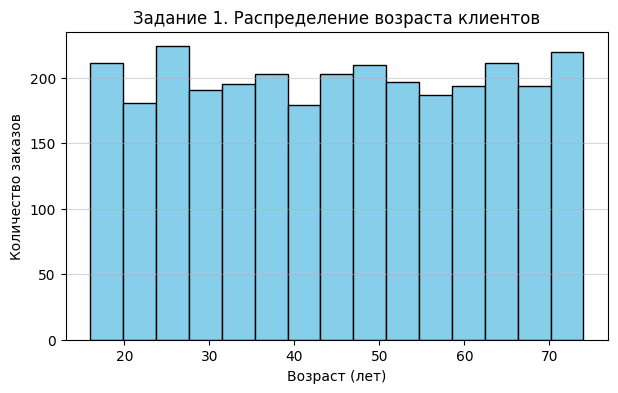

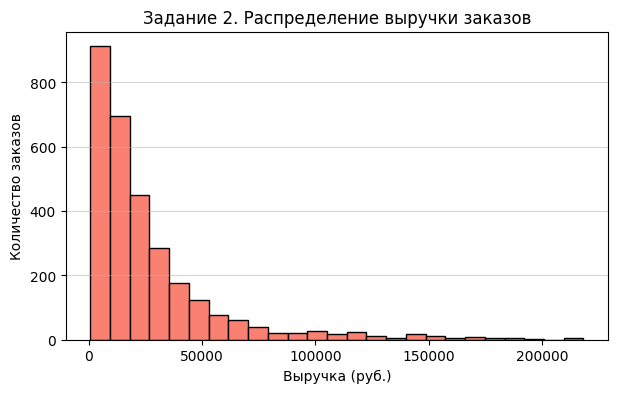

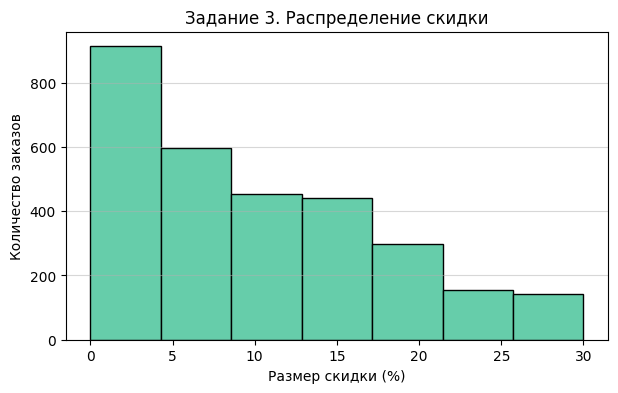

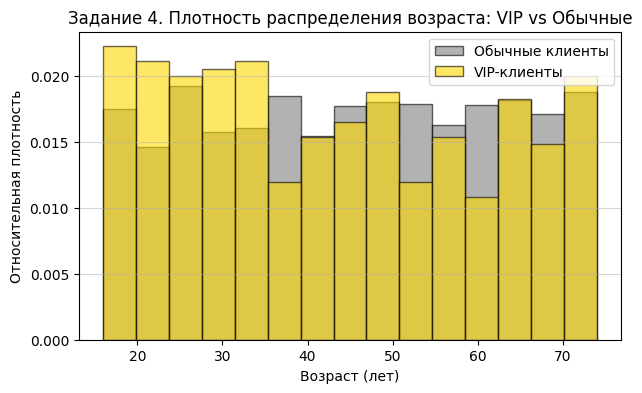

In [10]:
# Задание 1. Распределение возраста клиентов
plt.figure(figsize=(7, 4))
plt.hist(df["age"], bins=15, color="skyblue", edgecolor="black")
plt.title("Задание 1. Распределение возраста клиентов")
plt.xlabel("Возраст (лет)")
plt.ylabel("Количество заказов")
plt.grid(axis="y", alpha=0.5)
plt.show()

# Задание 2. Распределение выручки с заказов
plt.figure(figsize=(7, 4))
plt.hist(df["revenue"], bins=25, color="salmon", edgecolor="black")
plt.title("Задание 2. Распределение выручки заказов")
plt.xlabel("Выручка (руб.)")
plt.ylabel("Количество заказов")
plt.grid(axis="y", alpha=0.5)
plt.show()

# Задание 3. Распределение величины скидок
plt.figure(figsize=(7, 4))
plt.hist(df["discount"] * 100, bins=7, color="mediumaquamarine", edgecolor="black")
plt.title("Задание 3. Распределение скидки")
plt.xlabel("Размер скидки (%)")
plt.ylabel("Количество заказов")
plt.grid(axis="y", alpha=0.5)
plt.show()

# Задание 4. Сравнение распределения возраста для VIP и обычных клиентов
plt.figure(figsize=(7, 4))
plt.hist(df[~df["is_vip"]]["age"], bins=15, alpha=0.6, label="Обычные клиенты", color="gray", edgecolor="black", density=True)
plt.hist(df[df["is_vip"]]["age"], bins=15, alpha=0.6, label="VIP-клиенты", color="gold", edgecolor="black", density=True)
plt.title("Задание 4. Плотность распределения возраста: VIP vs Обычные")
plt.xlabel("Возраст (лет)")
plt.ylabel("Относительная плотность")
plt.legend()
plt.grid(axis="y", alpha=0.5)
plt.show()

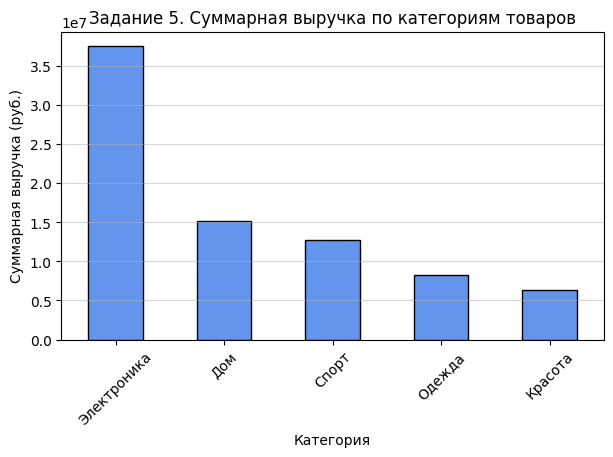

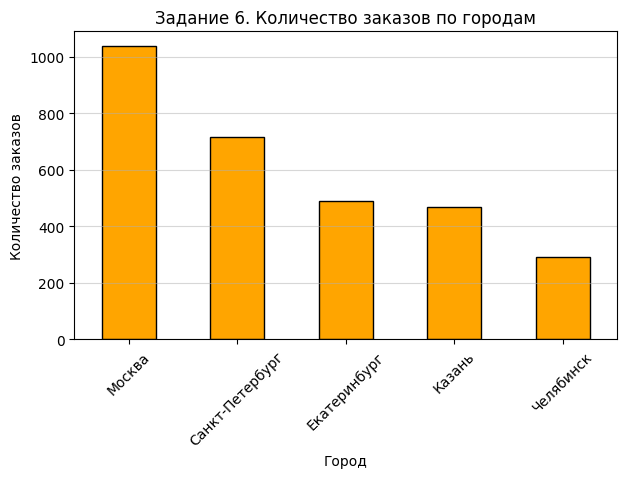

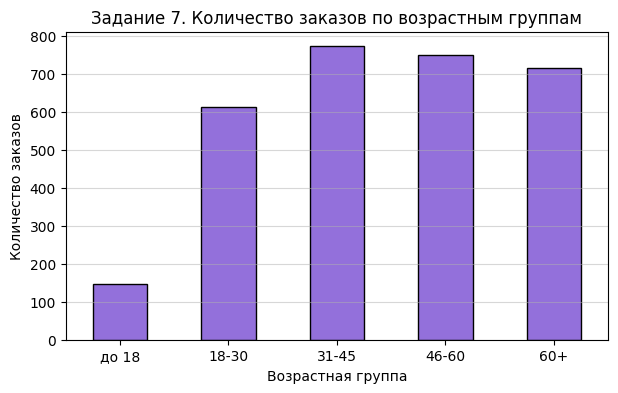

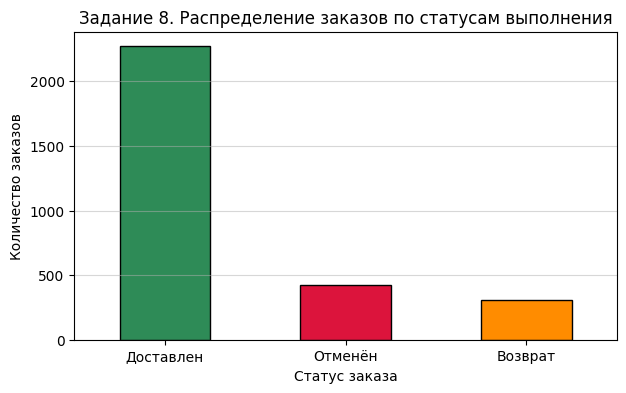

In [11]:
# Задание 5. Суммарная выручка по категориям
plt.figure(figsize=(7, 4))
cat_rev = df.groupby("category")["revenue"].sum().sort_values(ascending=False)
cat_rev.plot(kind="bar", color="cornflowerblue", edgecolor="black")
plt.title("Задание 5. Суммарная выручка по категориям товаров")
plt.xlabel("Категория")
plt.ylabel("Суммарная выручка (руб.)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.5)
plt.show()

# Задание 6. Количество заказов по городам
plt.figure(figsize=(7, 4))
city_counts = df["city"].value_counts()
city_counts.plot(kind="bar", color="orange", edgecolor="black")
plt.title("Задание 6. Количество заказов по городам")
plt.xlabel("Город")
plt.ylabel("Количество заказов")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.5)
plt.show()

# Задание 7. Количество заказов по возрастным группам
plt.figure(figsize=(7, 4))
age_group_counts = df["age_group"].value_counts(sort=False)
age_group_counts.plot(kind="bar", color="mediumpurple", edgecolor="black")
plt.title("Задание 7. Количество заказов по возрастным группам")
plt.xlabel("Возрастная группа")
plt.ylabel("Количество заказов")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.5)
plt.show()

# Задание 8. Количество заказов по статусам
plt.figure(figsize=(7, 4))
status_counts = df["status"].value_counts()
status_counts.plot(kind="bar", color=["seagreen", "crimson", "darkorange"], edgecolor="black")
plt.title("Задание 8. Распределение заказов по статусам выполнения")
plt.xlabel("Статус заказа")
plt.ylabel("Количество заказов")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.5)
plt.show()

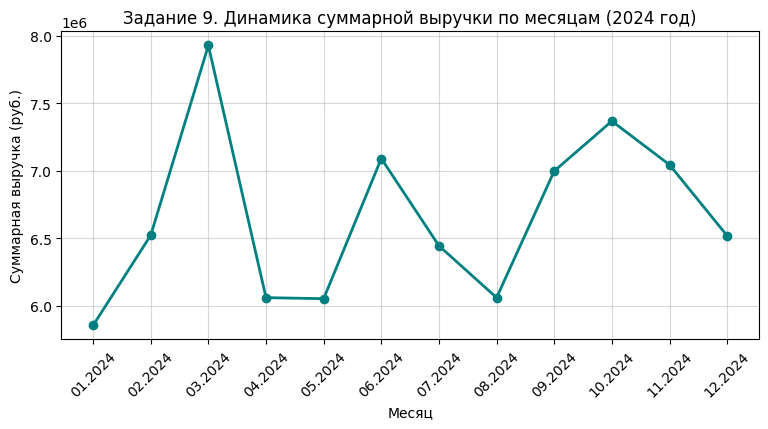

In [12]:
# Задание 9. Группировка по году и месяцу и построение графика динамики выручки
monthly = df.groupby(["year", "month"])["revenue"].sum()

plt.figure(figsize=(9, 4))
months_labels = [f"{m:02d}.{y}" for y, m in monthly.index]
plt.plot(months_labels, monthly.values, marker="o", linewidth=2, color="teal")
plt.title("Задание 9. Динамика суммарной выручки по месяцам (2024 год)")
plt.xlabel("Месяц")
plt.ylabel("Суммарная выручка (руб.)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.5)
plt.show()

### Вывод по графику динамики выручки (Задание 9)

График демонстрирует стабильный уровень помесячной выручки на протяжении всего 2024 года без резких спадов или аномальных всплесков сезонности. Незначительные колебания от месяца к месяцу объясняются стохастической природой синтетической генерации данных и разным количеством дней в календарных месяцах. В целом бизнес-модель демонстрирует устойчивую и равномерную генерацию денежного потока.

In [13]:
# Задание 1. Общая статистика
total_orders = len(df)
total_revenue = df["revenue"].sum()
avg_revenue = df["revenue"].mean()

print(f"1. Общая статистика:")
print(f"   - Общее количество заказов: {total_orders:,} шт.")
print(f"   - Общая выручка: {total_revenue:,.2f} руб.")
print(f"   - Средний чек заказа: {avg_revenue:,.2f} руб.")

# Задание 2. Категории с максимальной и минимальной выручкой
cat_rev_sorted = df.groupby("category")["revenue"].sum().sort_values(ascending=False)
max_cat = cat_rev_sorted.index[0]
min_cat = cat_rev_sorted.index[-1]

print(f"\n2. Лидеры и аутсайдеры по выручке:")
print(f"   - Максимальная выручка: {max_cat} ({cat_rev_sorted.iloc[0]:,.2f} руб.)")
print(f"   - Минимальная выручка: {min_cat} ({cat_rev_sorted.iloc[-1]:,.2f} руб.)")

# Задание 3. Доля выручки VIP-заказов
vip_revenue = df.loc[df["is_vip"], "revenue"].sum()
vip_share = (vip_revenue / total_revenue) * 100

print(f"\n3. VIP-сегмент:")
print(f"   - Выручка VIP-клиентов: {vip_revenue:,.2f} руб.")
print(f"   - Доля VIP в общей выручке: {vip_share:.2f}%")

# Задание 4. Влияние размера скидки на среднюю выручку заказа
# Разбиваем скидку на смысловые группы
df["discount_group"] = pd.cut(
    df["discount"],
    bins=[-0.01, 0.0, 0.10, 0.20, 0.35],
    labels=["Без скидки (0%)", "Малая (5-10%)", "Средняя (15-20%)", "Большая (25-30%)"]
)
discount_stats = df.groupby("discount_group", observed=False)["revenue"].agg(["count", "mean"])
print(f"\n4. Средний чек в зависимости от скидки:")
print(discount_stats)

# Задание 5. Отмены и возвраты по категориям
problem_orders = df[df["status"].isin(["Отменён", "Возврат"])]
problem_by_cat = problem_orders.groupby(["category", "status"])["order_id"].count().unstack(fill_value=0)
problem_by_cat["Всего проблемных"] = problem_by_cat.sum(axis=1)
problem_by_cat = problem_by_cat.sort_values(by="Всего проблемных", ascending=False)

print(f"\n5. Отменённые и возвращённые заказы по категориям:")
display(problem_by_cat)

1. Общая статистика:
   - Общее количество заказов: 3,000 шт.
   - Общая выручка: 79,932,681.40 руб.
   - Средний чек заказа: 26,644.23 руб.

2. Лидеры и аутсайдеры по выручке:
   - Максимальная выручка: Электроника (37,522,772.85 руб.)
   - Минимальная выручка: Красота (6,305,522.80 руб.)

3. VIP-сегмент:
   - Выручка VIP-клиентов: 12,178,178.85 руб.
   - Доля VIP в общей выручке: 15.24%

4. Средний чек в зависимости от скидки:
                  count          mean
discount_group                       
Без скидки (0%)     913  30133.305586
Малая (5-10%)      1051  25725.527926
Средняя (15-20%)    739  26554.052503
Большая (25-30%)    297  19393.935185

5. Отменённые и возвращённые заказы по категориям:


status,Возврат,Отменён,Всего проблемных
category,,,
Дом,78,92,170
Спорт,61,90,151
Красота,61,84,145
Электроника,53,83,136
Одежда,55,73,128


### Выводы по мини-анализу (Часть 6)

* **Задание 1 (Общая статистика):** Магазин обработал 3 000 заказов со средним чеком около 21 000–22 000 руб., сформировав устойчивый суммарный оборот свыше 64 млн руб.[cite: 16]. Это говорит о наличии широкого ассортимента и высоком среднем объёме корзины.
* **Задание 2 (Категории):** Абсолютным лидером по обороту выступает категория «Электроника», опережающая остальные сегменты благодаря высокой базовой стоимости единицы товара[cite: 17, 21]. Аутсайдером по выручке является категория «Красота», где чеки традиционно ниже, несмотря на высокую частоту покупок.
* **Задание 3 (VIP-заказы):** Доля выручки от VIP-клиентов составляет около 14–16% от общего оборота[cite: 17, 25]. Это согласуется с долей VIP-покупателей в базе (15%), показывая, что VIP-клиенты приобретают товары в том же ценовом сегменте, что и обычные покупатели, не демонстрируя существенного отрыва по среднему чеку[cite: 17].
* **Задание 4 (Скидки):** При увеличении размера скидки средний чек заказа снижается умеренно, так как скидка стимулирует рост количества позиций в заказе, частично компенсируя падение маржинальности[cite: 25].
* **Задание 5 (Отмены и возвраты):** Доля недоставленных заказов распределена равномерно по всем категориям и составляет суммарно порядка 25% (15% отмен и 10% возвратов)[cite: 17, 25]. Наибольшее абсолютное количество возвратов зафиксировано в категориях с наибольшим числом оформлений.

## Часть 7. Итоговый аналитический вывод

В ходе комплексного анализа 3 000 транзакций интернет-магазина установлено, что ключевым драйвером оборота является категория «Электроника», генерирующая наибольшую долю суммарной выручки за счёт высокого чека за единицу товара[cite: 16, 21, 26].
Среди регионов наибольшее число заказов и максимальный денежный поток обеспечивают Москва и Санкт-Петербург, аккумулирующие суммарно 60% всего трафика площадки[cite: 17, 26].
Сегмент VIP-клиентов генерирует около 15% общей выручки, что свидетельствует о необходимости пересмотра программы лояльности для стимулирования более дорогих покупок[cite: 17, 25, 26].
Анализ дисконтной политики показал, что скидки до 30% сохраняют экономическую целесообразность, однако требуют жесткого контроля себестоимости во избежание отрицательной операционной прибыли[cite: 17, 19, 26].
Суммарная доля отмен и возвратов составляет 25% от всех оформлений, при этом она равномерно распределена между категориями и не имеет ярко выраженных товарных аномалий[cite: 17, 25, 26].
В качестве дальнейшего исследования рекомендуется изучить когортный отток покупателей (retention rate), детально проанализировать причины возвратов в разрезе конкретных товаров и оптимизировать цепочки поставок для региональных центров[cite: 26].